In [1]:
pip install yfinance numpy pandas matplotlib statsmodels

Note: you may need to restart the kernel to use updated packages.


[*********************100%***********************]  1 of 2 completed


Apna P-Value aaya hai: 0.03560614489433847
Mast! P-value 0.05 se kam hai, matlab pair trading kar sakte hain.

--- Apne Data Ka Pehla 5 Row ---
            RELIANCE_Price  BPCL_Price      Spread   Z_Score
Date                                                        
2021-09-30     1141.013428  174.431412  871.857627 -0.623003
2021-10-01     1143.028809  174.774460  873.343668 -0.603019
2021-10-04     1157.726074  175.904480  886.297260 -0.428814
2021-10-05     1181.753418  179.133224  905.342500 -0.172687
2021-10-06     1159.401978  180.485245  880.904830 -0.501333


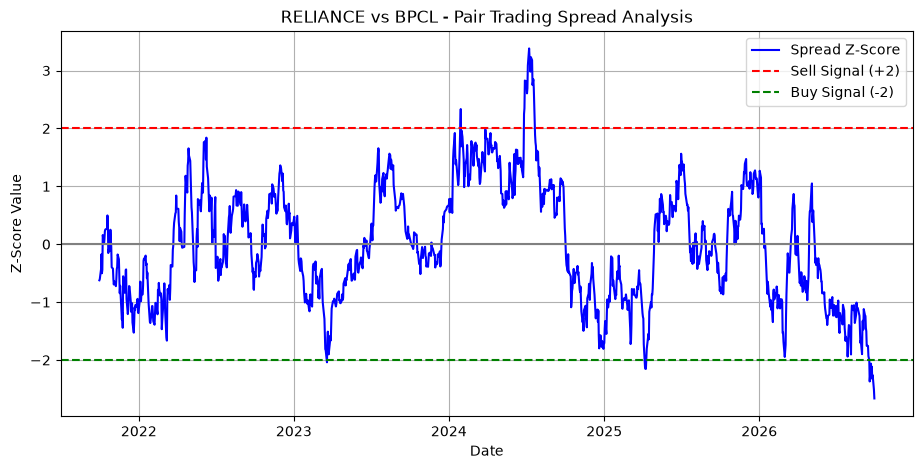

In [5]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

stocks = ['RELIANCE.NS', 'BPCL.NS']
df = yf.download(stocks, start="2021-09-30", end="2026-09-30")['Close']
df = df.dropna() 

s1 = df['RELIANCE.NS']
s2 = df['BPCL.NS']

score, p_val, _ = coint(s1, s2)
print("Apna P-Value aaya hai:", p_val)

if p_val < 0.05:
    print("Mast! P-value 0.05 se kam hai, matlab pair trading kar sakte hain.")
else:
    print("Dono stocks sath me nahi chal rahe, par test ke liye aage badhte hain.")

s2_constant = sm.add_constant(s2)
ols_model = sm.OLS(s1, s2_constant).fit()
beta_value = ols_model.params.iloc[1]

spread = s1 - (beta_value * s2)
z_score = (spread - spread.mean()) / spread.std()
final_data = pd.DataFrame({
    'RELIANCE_Price': s1,
    'BPCL_Price': s2,
    'Spread': spread,
    'Z_Score': z_score
})

print("\n--- Apne Data Ka Pehla 5 Row ---")
print(final_data.head())

plt.figure(figsize=(11, 5))
plt.plot(z_score, color='blue', label='Spread Z-Score')
plt.axhline(0, color='grey', linestyle='-')

plt.axhline(2, color='red', linestyle='--', label='Sell Signal (+2)')
plt.axhline(-2, color='green', linestyle='--', label='Buy Signal (-2)')

plt.title('RELIANCE vs BPCL - Pair Trading Spread Analysis')
plt.xlabel('Date')
plt.ylabel('Z-Score Value')
plt.legend()
plt.grid(True)
plt.show()



--- Strategy Results Calculated ---
Final Strategy Cumulative Return: 1.11x


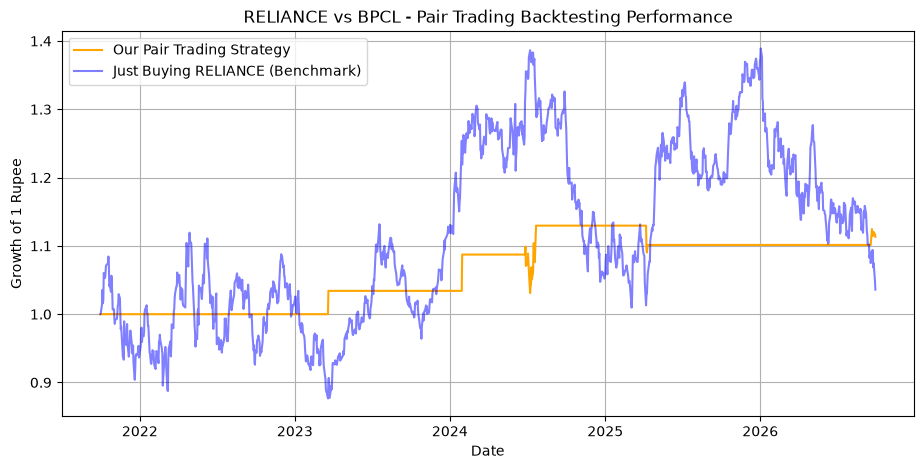

In [6]:
final_data['RELIANCE_Position'] = 0
final_data['BPCL_Position'] = 0

for i in range(len(final_data)):
    z = final_data['Z_Score'].iloc[i]
    
    if z > 2:
        # Spread bahut bada ho gaya hai, wapas niche aayega
        final_data.iloc[i, final_data.columns.get_loc('RELIANCE_Position')] = -1 # Short TCS
        final_data.iloc[i, final_data.columns.get_loc('BPCL_Position')] = 1  # Buy INFY
    elif z < -2:
        # Spread bahut chhota ho gaya hai, wapas upar aayega
        final_data.iloc[i, final_data.columns.get_loc('RELIANCE_Position')] = 1  # Buy TCS
        final_data.iloc[i, final_data.columns.get_loc('BPCL_Position')] = -1 # Short INFY
    elif abs(z) < 0.5:
        # Spread normal ho gaya, trades se bahar nikal jao
        final_data.iloc[i, final_data.columns.get_loc('RELIANCE_Position')] = 0
        final_data.iloc[i, final_data.columns.get_loc('BPCL_Position')] = 0

        # -- STEP 6: BACKTESTING ENGINE & RETURNS CALCULATION --
# Har stock ka daily returns nikalte hain
final_data['RELIANCE_Daily_Return'] = final_data['RELIANCE_Price'].pct_change()
final_data['BPCL_Daily_Return'] = final_data['BPCL_Price'].pct_change()

# Humne jo position li thi, usko pichle din ke return se multiply karenge
# Shift(1) isliye lagaya kyunki trade lene ke agle din se profit/loss shuru hota hai
final_data['Strategy_Return'] = (final_data['RELIANCE_Position'].shift(1) * final_data['RELIANCE_Daily_Return'] + 
                                 final_data['BPCL_Position'].shift(1) * final_data['BPCL_Daily_Return'])

# Total equity growth dekhne ke liye cumulative returns nikalte hain
final_data['Cumulative_Strategy'] = (1 + final_data['Strategy_Return'].fillna(0)).cumprod()
final_data['Cumulative_RELIANCE_Hold'] = (1 + final_data['RELIANCE_Daily_Return'].fillna(0)).cumprod()

print("\n--- Strategy Results Calculated ---")
print(f"Final Strategy Cumulative Return: {final_data['Cumulative_Strategy'].iloc[-1]:.2f}x")

# -- STEP 7: STRATEGY PERFORMANCE GRAPH --
# Ab performance ka graph plots karte hain
plt.figure(figsize=(11, 5))
plt.plot(final_data['Cumulative_Strategy'], color='orange', label='Our Pair Trading Strategy')
plt.plot(final_data['Cumulative_RELIANCE_Hold'], color='blue', alpha=0.5, label='Just Buying RELIANCE (Benchmark)')
plt.title('RELIANCE vs BPCL - Pair Trading Backtesting Performance')
plt.xlabel('Date')
plt.ylabel('Growth of 1 Rupee')
plt.legend()
plt.grid(True)
plt.show()